# ***State Classification***

## **Data and Libraries Import**

`Libraries import`

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import os
from pathlib import Path
from dotenv import load_dotenv,find_dotenv

from sqlalchemy import create_engine, text


import warnings
warnings.filterwarnings('ignore')

`Initializing the env-variables so that no one sees the actual credentials`

In [2]:
env_path = Path.cwd()/"github_repo_cloned"/"distribution_hub_optimizer"/".env"
load_dotenv(env_path)

HOST = os.getenv("DB_HOST")
USER = os.getenv("DB_USER")
PASSWORD = os.getenv("DB_PASSWORD")
PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
OUTPUT_DIR = Path(os.getenv("OUTPUT_DIR", Path.cwd()/"outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

`Creating the engine to connect with the database`

In [3]:
engine = create_engine(f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DB_NAME}")


def sql(query, engine = engine):
    with engine.connect() as conn:
        df = pd.read_sql(text(query),conn)
    return df

In [4]:
query = 'select * from gain_classification'

data = sql(query=query, engine=engine)

In [5]:
data.head()

,state,from_fy,to_fy,per_capita_gain_pct,gsdp_gain_pct,gain_gap_pct,gain_class
0,jammu and kashmir,2019-20,2023-24,81.58,50.19,31.39,goods outgrowing economy
1,himachal pradesh,2019-20,2023-24,44.44,30.32,14.12,goods outgrowing economy
2,punjab,2019-20,2023-24,68.86,37.13,31.73,goods outgrowing economy
3,haryana,2019-20,2023-24,70.23,48.44,21.79,goods outgrowing economy
4,delhi,2019-20,2023-24,35.91,39.71,-3.80,goods lagging economy


## **Initial Data Check**

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   state                33 non-null     object 
 1   from_fy              33 non-null     object 
 2   to_fy                33 non-null     object 
 3   per_capita_gain_pct  33 non-null     float64
 4   gsdp_gain_pct        33 non-null     float64
 5   gain_gap_pct         33 non-null     float64
 6   gain_class           33 non-null     object 
dtypes: float64(3), object(4)
memory usage: 1.9+ KB


In [7]:
print("Any Duplicate Values?")
print(f"States: {data['state'].duplicated().sum()}")

Any Duplicate Values?
States: 0


In [8]:
print("Any Null Values?")
data.isnull().sum()

Any Null Values?


state                  0
from_fy                0
to_fy                  0
per_capita_gain_pct    0
gsdp_gain_pct          0
gain_gap_pct           0
gain_class             0
dtype: int64

In [9]:
# Window used for the gains (same for every state)
data[['from_fy','to_fy']].drop_duplicates()

,from_fy,to_fy
0,2019-20,2023-24


In [10]:
print(f"States in view: {data['state'].nunique()}")
sorted(data['state'].str.title())

States in view: 33


['Andaman And Nicobar',
 'Andhra Pradesh',
 'Arunachal Pradesh',
 'Assam',
 'Bihar',
 'Chandigarh',
 'Chhattisgarh',
 'Delhi',
 'Goa',
 'Gujarat',
 'Haryana',
 'Himachal Pradesh',
 'Jammu And Kashmir',
 'Jharkhand',
 'Karnataka',
 'Kerala',
 'Madhya Pradesh',
 'Maharashtra',
 'Manipur',
 'Meghalaya',
 'Mizoram',
 'Nagaland',
 'Odisha',
 'Puducherry',
 'Punjab',
 'Rajasthan',
 'Sikkim',
 'Tamil Nadu',
 'Telangana',
 'Tripura',
 'Uttar Pradesh',
 'Uttarakhand',
 'West Bengal']

`The statistics of numerical columns`

In [11]:
num_cols = ['per_capita_gain_pct','gsdp_gain_pct','gain_gap_pct']
data[num_cols].describe().round(2)

,per_capita_gain_pct,gsdp_gain_pct,gain_gap_pct
count,33.00,33.00,33.00
mean,68.62,45.79,22.82
std,22.67,8.78,19.97
min,15.09,26.88,-18.07
25%,54.65,40.98,7.00
50%,68.86,46.85,22.60
75%,85.99,52.40,33.28
max,121.43,63.01,74.91


In [12]:
# Gap in the view must equal per capita gain minus GSDP gain
print("Max difference:", (data['per_capita_gain_pct'] - data['gsdp_gain_pct'] - data['gain_gap_pct']).abs().max().round(2))

Max difference: 0.0


In [13]:
# The view already has a quick label, keep it for comparison with the final classes
data = data.rename(columns={'gain_class':'quick_class'})
data.head()

,state,from_fy,to_fy,per_capita_gain_pct,gsdp_gain_pct,gain_gap_pct,quick_class
0,jammu and kashmir,2019-20,2023-24,81.58,50.19,31.39,goods outgrowing economy
1,himachal pradesh,2019-20,2023-24,44.44,30.32,14.12,goods outgrowing economy
2,punjab,2019-20,2023-24,68.86,37.13,31.73,goods outgrowing economy
3,haryana,2019-20,2023-24,70.23,48.44,21.79,goods outgrowing economy
4,delhi,2019-20,2023-24,35.91,39.71,-3.80,goods lagging economy


## **Classification**

`Class distribution`

In [1]:
IN_LINE_BAND = 10
STRONG_BAND = 30

CLASS_ORDER = ['Strong Outperformer','Outperformer','In Line','Underperformer','Strong Underperformer','Declining']
CLASS_COLORS = {
    'Strong Outperformer':'#1a9850',
    'Outperformer':'#91cf60',
    'In Line':'#bdbdbd',
    'Underperformer':'#fc8d59',
    'Strong Underperformer':'#d73027',
    'Declining':'#542788'
}

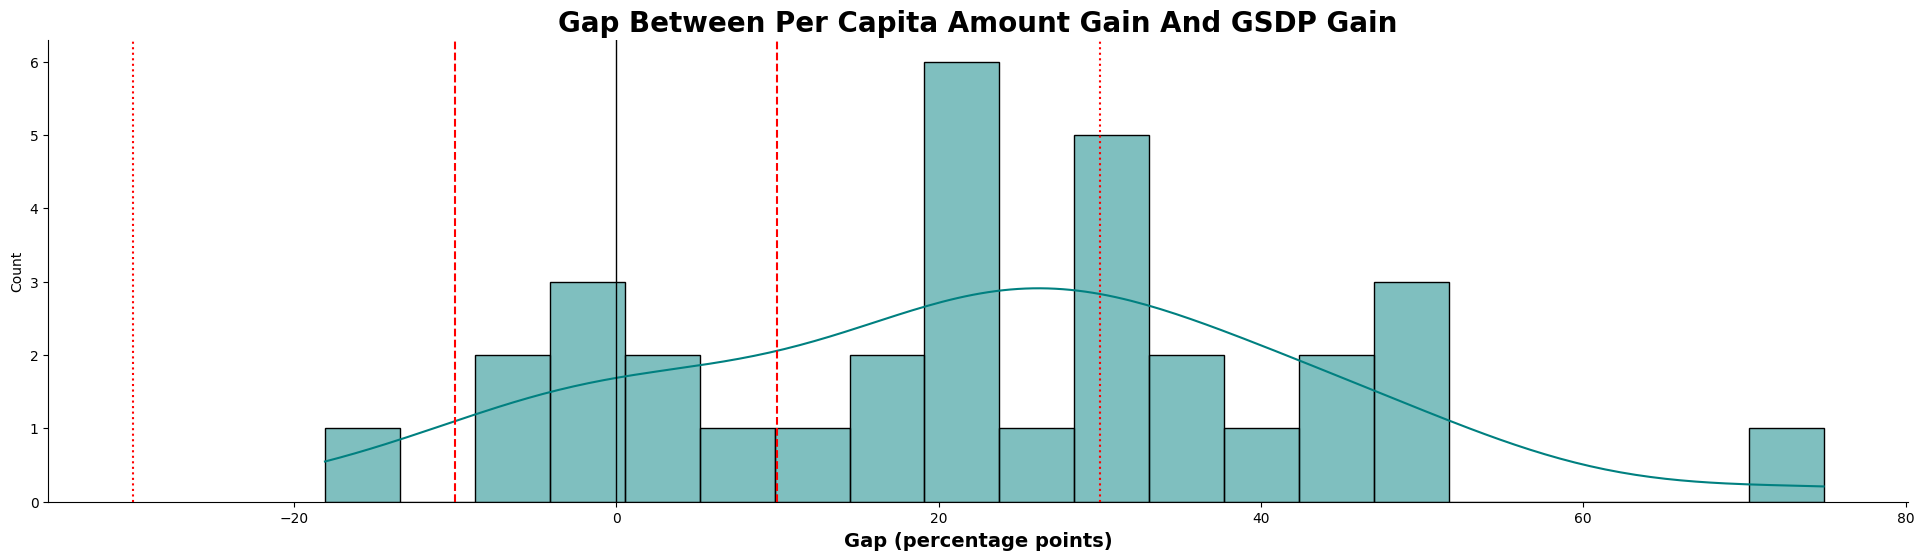

In [15]:
plt.figure(figsize=(24,6))
sns.histplot(data['gain_gap_pct'], bins=20, kde=True, color='teal')
for band, style in [(IN_LINE_BAND,'--'),(STRONG_BAND,':')]:
    plt.axvline(band, color='red', linestyle=style)
    plt.axvline(-band, color='red', linestyle=style)
plt.axvline(0, color='black', linewidth=1)
plt.title('Gap Between Per Capita Amount Gain And GSDP Gain',fontsize=20,weight='bold')
plt.xlabel('Gap (percentage points)',fontsize=14,weight='bold')
sns.despine()
plt.show()

`Adding classes`

In [16]:
def classify(row):
    gap = row['gain_gap_pct']
    if row['per_capita_gain_pct'] < 0:
        return 'Declining'
    if gap >= STRONG_BAND:
        return 'Strong Outperformer'
    if gap >= IN_LINE_BAND:
        return 'Outperformer'
    if gap > -IN_LINE_BAND:
        return 'In Line'
    if gap > -STRONG_BAND:
        return 'Underperformer'
    return 'Strong Underperformer'


data['state_class'] = data.apply(classify, axis=1)
data['state_class'] = pd.Categorical(data['state_class'], categories=CLASS_ORDER, ordered=True)
data = data.sort_values(['state_class','gain_gap_pct'], ascending=[True, False]).reset_index(drop=True)
data.head()

,state,from_fy,to_fy,per_capita_gain_pct,gsdp_gain_pct,gain_gap_pct,quick_class,state_class
0,arunachal pradesh,2019-20,2023-24,121.43,46.52,74.91,goods outgrowing economy,Strong Outperformer
1,tripura,2019-20,2023-24,102.78,52.58,50.20,goods outgrowing economy,Strong Outperformer
2,chhattisgarh,2019-20,2023-24,95.24,46.77,48.47,goods outgrowing economy,Strong Outperformer
3,meghalaya,2019-20,2023-24,84.00,36.27,47.73,goods outgrowing economy,Strong Outperformer
4,odisha,2019-20,2023-24,99.15,54.94,44.21,goods outgrowing economy,Strong Outperformer


`Class Summary`

In [17]:
class_summary = data.groupby('state_class', observed=True).agg(
    states=('state','count'),
    avg_per_capita_gain_pct=('per_capita_gain_pct','mean'),
    avg_gsdp_gain_pct=('gsdp_gain_pct','mean'),
    avg_gap_pct=('gain_gap_pct','mean'),
    state_list=('state', lambda s: ', '.join(s.str.title()))
).round(2).reset_index()

class_summary

,state_class,states,avg_per_capita_gain_pct,avg_gsdp_gain_pct,avg_gap_pct,state_list
0,Strong Outperformer,13,88.64,46.96,41.68,"Arunachal Pradesh, Tripura, Chhattisgarh, Megh..."
1,Outperformer,11,66.33,45.17,21.16,"Nagaland, Gujarat, Maharashtra, Rajasthan, Goa..."
2,In Line,8,45.91,46.33,-0.42,"Andaman And Nicobar, Uttar Pradesh, Chandigarh..."
3,Underperformer,1,15.09,33.16,-18.07,Mizoram


In [ ]:
pd.crosstab(data['state_class'], data['quick_class'])

quick_class,goods lagging economy,goods outgrowing economy
state_class,,
Strong Outperformer,0,13
Outperformer,0,11
In Line,5,3
Underperformer,1,0


In [19]:
print("Top 5 states where goods per person outgrew the economy:")
data.nlargest(5, 'gain_gap_pct')[['state','per_capita_gain_pct','gsdp_gain_pct','gain_gap_pct','state_class']]

Top 5 states where goods per person outgrew the economy:


,state,per_capita_gain_pct,gsdp_gain_pct,gain_gap_pct,state_class
0,arunachal pradesh,121.43,46.52,74.91,Strong Outperformer
1,tripura,102.78,52.58,50.20,Strong Outperformer
2,chhattisgarh,95.24,46.77,48.47,Strong Outperformer
3,meghalaya,84.00,36.27,47.73,Strong Outperformer
4,odisha,99.15,54.94,44.21,Strong Outperformer


In [20]:
print("Top 5 states where goods per person lagged the economy:")
data.nsmallest(5, 'gain_gap_pct')[['state','per_capita_gain_pct','gsdp_gain_pct','gain_gap_pct','state_class']]

Top 5 states where goods per person lagged the economy:


,state,per_capita_gain_pct,gsdp_gain_pct,gain_gap_pct,state_class
32,mizoram,15.09,33.16,-18.07,Underperformer
31,manipur,40.00,45.66,-5.66,In Line
30,uttarakhand,40.05,44.70,-4.65,In Line
29,delhi,35.91,39.71,-3.80,In Line
28,sikkim,54.65,55.65,-1.00,In Line


`Visualization`

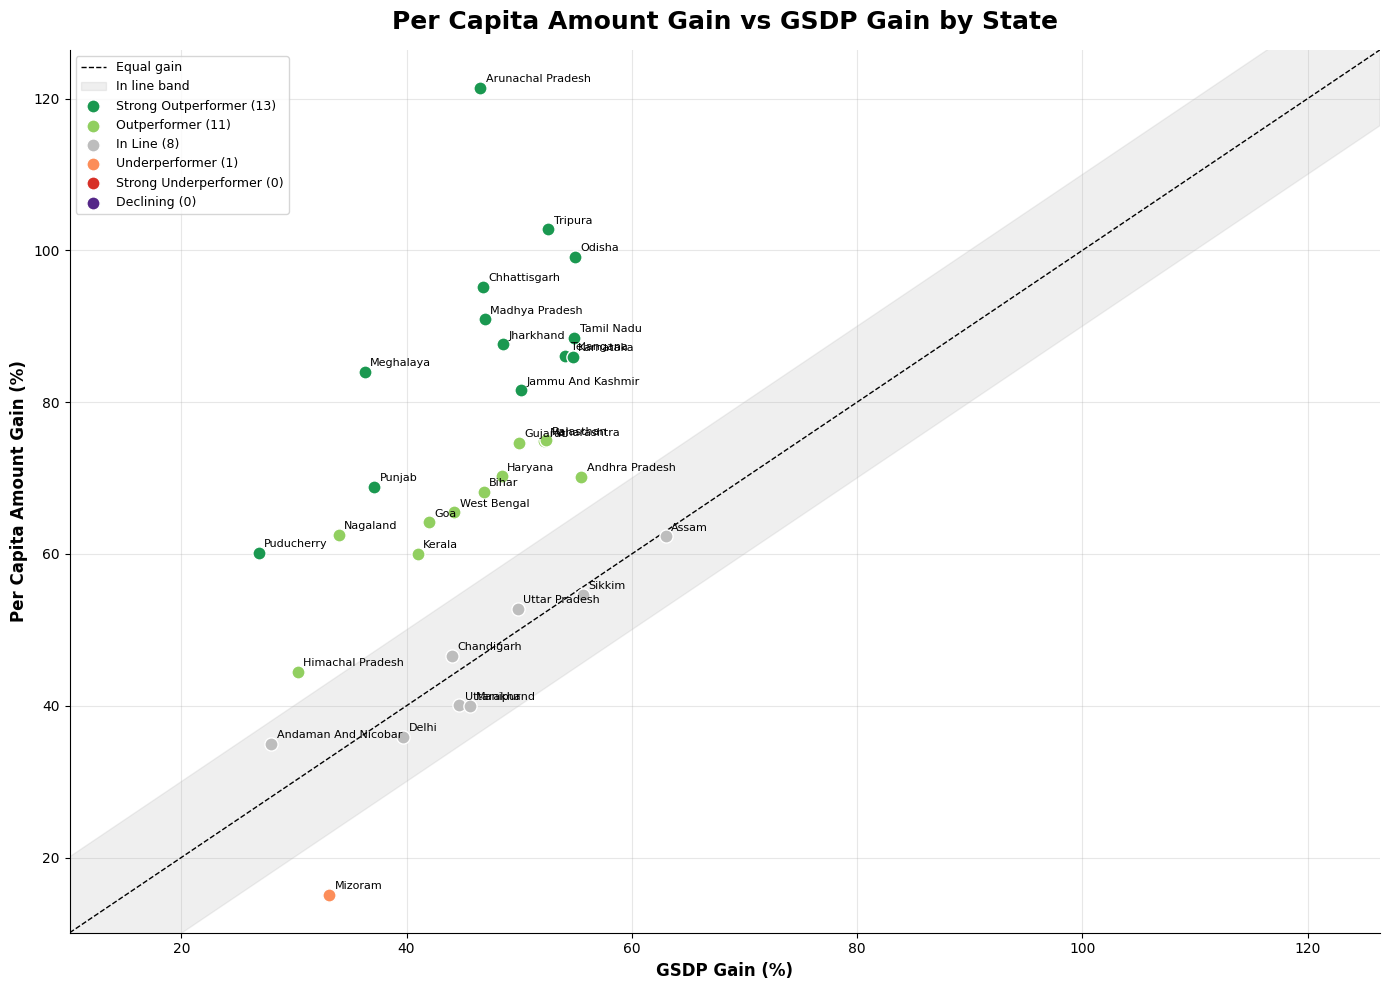

In [21]:
fig, ax = plt.subplots(figsize=(14,10))

x = data['gsdp_gain_pct']
y = data['per_capita_gain_pct']
lims = [min(x.min(), y.min()) - 5, max(x.max(), y.max()) + 5]

# Equal gain line with the in line band around it
ax.plot(lims, lims, color='black', linestyle='--', linewidth=1, label='Equal gain')
ax.fill_between(lims, [l - IN_LINE_BAND for l in lims], [l + IN_LINE_BAND for l in lims], color='grey', alpha=0.12, label='In line band')

for cls in CLASS_ORDER:
    sub = data[data['state_class'] == cls]
    ax.scatter(sub['gsdp_gain_pct'], sub['per_capita_gain_pct'], s=90, color=CLASS_COLORS[cls],
               edgecolor='white', label=f"{cls} ({len(sub)})", zorder=3)

for _, r in data.iterrows():
    ax.annotate(r['state'].title(), (r['gsdp_gain_pct'], r['per_capita_gain_pct']),
                xytext=(4,4), textcoords='offset points', fontsize=8)

ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_title('Per Capita Amount Gain vs GSDP Gain by State', fontweight='bold', fontsize=18, pad=15)
ax.set_xlabel('GSDP Gain (%)', fontsize=12, weight='bold')
ax.set_ylabel('Per Capita Amount Gain (%)', fontsize=12, weight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"state_class_scatter.png", dpi=150, bbox_inches='tight')
plt.show()

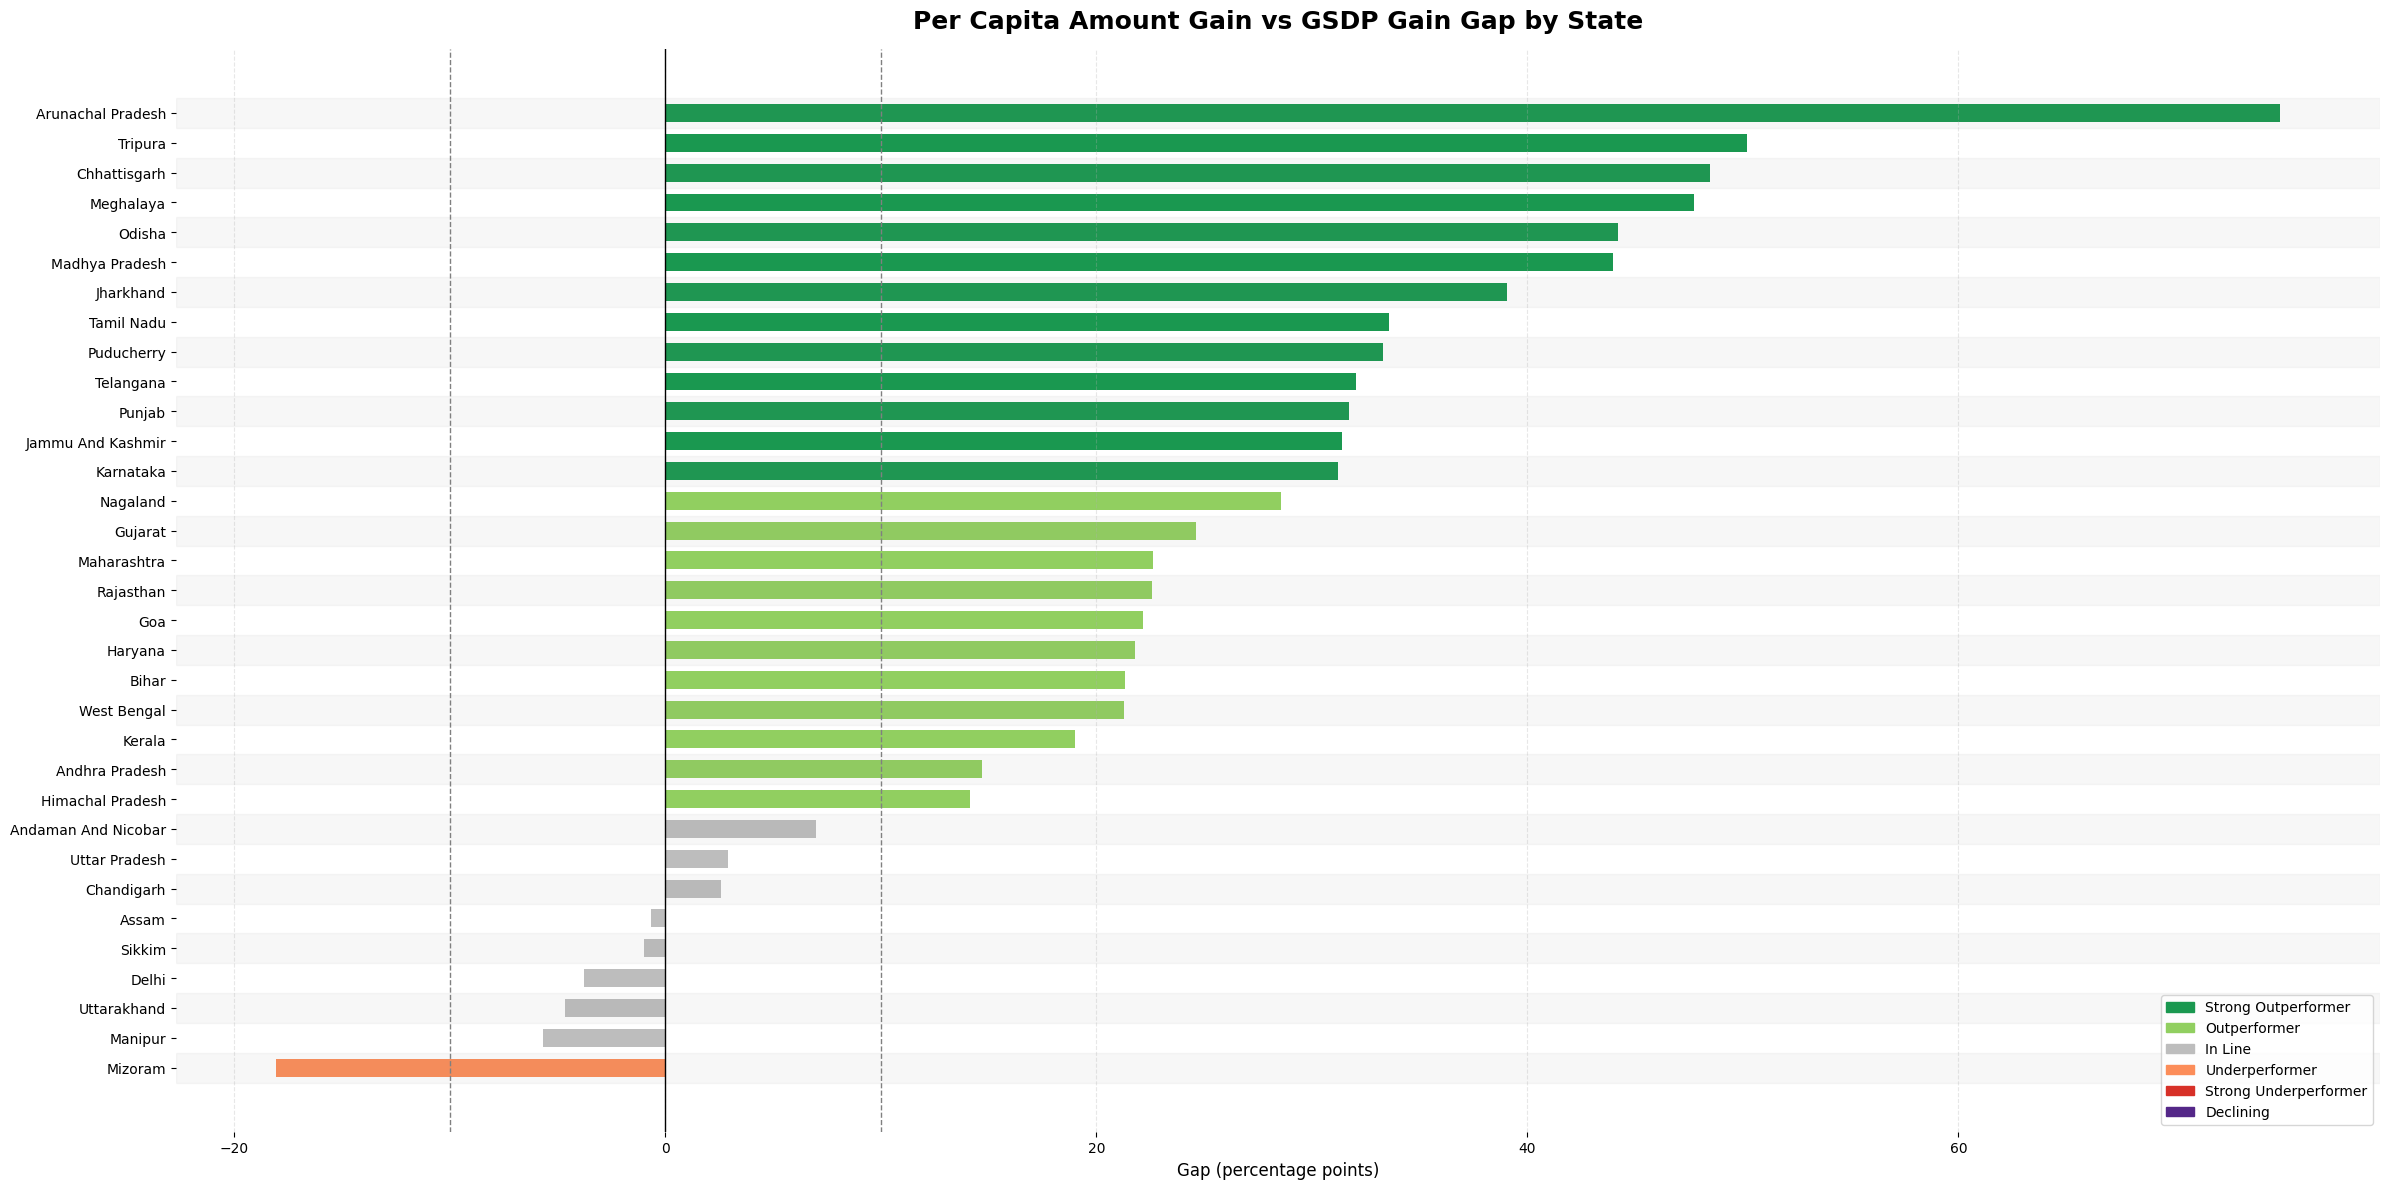

In [22]:
plot_df = data.sort_values('gain_gap_pct').reset_index(drop=True)
colors = plot_df['state_class'].astype(str).map(CLASS_COLORS)

fig, ax = plt.subplots(figsize=(24,12))
ax.barh(plot_df['state'].str.title(), plot_df['gain_gap_pct'], color=colors, height=0.6)

# Alternating row bands so each label lines up with its bar
for i in range(len(plot_df)):
    if i % 2 == 0:
        ax.axhspan(i - 0.5, i + 0.5, color='grey', alpha=0.06)

ax.axvline(0, color='black', linewidth=1)
for band in [IN_LINE_BAND, -IN_LINE_BAND]:
    ax.axvline(band, color='grey', linestyle='--', linewidth=1)

handles = [plt.Rectangle((0,0),1,1,color=CLASS_COLORS[c]) for c in CLASS_ORDER]
ax.legend(handles, CLASS_ORDER, loc='lower right')
ax.set_title('Per Capita Amount Gain vs GSDP Gain Gap by State', fontweight='bold', fontsize=18, pad=15)
ax.set_xlabel('Gap (percentage points)', fontsize=12)
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.tick_params(axis='y', labelsize=10)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"state_class_gap.png", dpi=150, bbox_inches='tight')
plt.show()

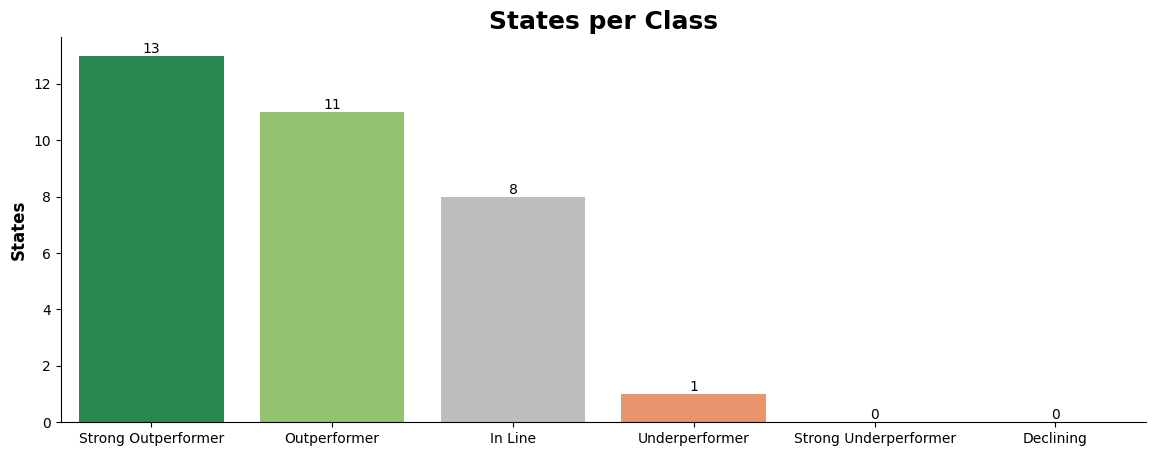

In [23]:
counts = data['state_class'].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)

plt.figure(figsize=(14,5))
ax = sns.barplot(x=counts.index, y=counts.values, palette=[CLASS_COLORS[c] for c in counts.index])
for container in ax.containers:
    ax.bar_label(container=container)
plt.title('States per Class', fontsize=18, weight='bold')
plt.xlabel('')
plt.ylabel('States', fontsize=12, weight='bold')
sns.despine()
plt.show()

`Save Outputs`

In [24]:
state_class = data[['state','from_fy','to_fy','per_capita_gain_pct','gsdp_gain_pct','gain_gap_pct','quick_class','state_class']]
state_class.to_csv(OUTPUT_DIR/"state_classification.csv", index=False)

In [25]:
class_summary.to_csv(OUTPUT_DIR/"state_class_summary.csv", index=False)